# Librerias

In [2]:
!pip install -r ../requirements.txt


[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, date, timedelta
import seaborn as sns
from typing import Optional

import os
import pickle

from sklearn import preprocessing
import importlib

from optbinning import OptimalBinning, BinningProcess

#from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Carga Data

In [4]:
df_data = pd.read_csv(
    "../data/02_intermediate/Base_preselected.csv",
    dtype={

    },
)

In [5]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_4w,...,period,address_stability_ratio,digital_identity_score,velocity_ratio_6h_24h,velocity_ratio_24h_4w,device_trust_score,email_risk_score,credit_limit_income_ratio,credit_risk_limit_ratio,contact_consistency
0,0,0.3,0.986506,NaN,40,0.006735,102.453711,AA,1059,6742.080561,...,2024-01-01,NaN,1,1.668082,1.164471,1,0.067468,5000.000000,0.222,0
1,0,0.8,0.617426,NaN,20,0.010095,-0.849551,AD,1658,5941.664859,...,2024-01-01,NaN,2,1.605375,0.966943,1,6.886332,1875.000000,0.216,1
2,0,0.8,0.996707,9.0,40,0.012316,-1.490386,AB,1095,5992.555113,...,2024-01-01,1.555556,1,0.817157,0.913131,2,0.036223,250.000000,1.295,0
3,0,0.6,0.475100,11.0,30,0.006991,-1.863101,AB,3483,5970.336831,...,2024-01-01,1.272727,1,2.136382,1.131485,1,6.823701,333.333333,1.300,0
4,0,0.9,0.842307,NaN,40,5.742626,47.152498,AA,2339,5940.734212,...,2024-01-01,NaN,3,1.483498,0.862528,2,0.946159,222.222222,1.305,1


In [6]:
df_data.shape

(1000000, 34)

In [7]:
df_data.dtypes

target                                int64
income                              float64
name_email_similarity               float64
prev_address_months_count           float64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                         object
zip_count_4w                          int64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                    object
credit_risk_score                     int64
email_is_free                         int64
housing_status                       object
phone_mobile_valid                    int64
bank_months_count                   float64
has_other_cards                       int64
foreign_request                       int64
source                               object
session_length_in_minutes           float64
device_os                       

In [8]:
# Mostrar todas las filas
pd.set_option("display.max_rows", None)

# Mostrar todas las columnas
pd.set_option("display.max_columns", None)

# No truncar el ancho de la salida
pd.set_option("display.width", None)

# No truncar el contenido de las columnas
pd.set_option("display.max_colwidth", None)

In [9]:
# Quiero que se muestre todos los registros del dataframe y no esto "..."
df_data.isna().sum()

target                                   0
income                                   0
name_email_similarity                    0
prev_address_months_count           712920
customer_age                             0
days_since_request                       0
intended_balcon_amount                   0
payment_type                             0
zip_count_4w                             0
velocity_4w                              0
bank_branch_count_8w                     0
date_of_birth_distinct_emails_4w         0
employment_status                        0
credit_risk_score                        0
email_is_free                            0
housing_status                           0
phone_mobile_valid                       0
bank_months_count                   253635
has_other_cards                          0
foreign_request                          0
source                                   0
session_length_in_minutes             2015
device_os                                0
device_dist

In [10]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_mobile_valid,bank_months_count,has_other_cards,foreign_request,source,session_length_in_minutes,device_os,device_distinct_emails_8w,period,address_stability_ratio,digital_identity_score,velocity_ratio_6h_24h,velocity_ratio_24h_4w,device_trust_score,email_risk_score,credit_limit_income_ratio,credit_risk_limit_ratio,contact_consistency
0,0,0.3,0.986506,NaN,40,0.006735,102.453711,AA,1059,6742.080561,5,5,CB,163,1,BC,1,9.0,0,0,INTERNET,16.224843,linux,1,2024-01-01,NaN,1,1.668082,1.164471,1,0.067468,5000.000000,0.222,0
1,0,0.8,0.617426,NaN,20,0.010095,-0.849551,AD,1658,5941.664859,3,18,CA,154,1,BC,1,2.0,0,0,INTERNET,3.363854,other,1,2024-01-01,NaN,2,1.605375,0.966943,1,6.886332,1875.000000,0.216,1
2,0,0.8,0.996707,9.0,40,0.012316,-1.490386,AB,1095,5992.555113,15,11,CA,89,1,BC,1,30.0,0,0,INTERNET,22.730559,windows,1,2024-01-01,1.555556,1,0.817157,0.913131,2,0.036223,250.000000,1.295,0
3,0,0.6,0.475100,11.0,30,0.006991,-1.863101,AB,3483,5970.336831,11,13,CA,90,1,BC,1,1.0,0,0,INTERNET,15.215816,linux,1,2024-01-01,1.272727,1,2.136382,1.131485,1,6.823701,333.333333,1.300,0
4,0,0.9,0.842307,NaN,40,5.742626,47.152498,AA,2339,5940.734212,1,6,CA,91,0,BC,1,26.0,0,0,INTERNET,3.743048,other,1,2024-01-01,NaN,3,1.483498,0.862528,2,0.946159,222.222222,1.305,1


# Split Data

In [11]:
# Quiero dividir df_data en train, test y oot. Train con period 2024-01-01 a 2024-06-30, test con period 2024-07-01 a 2024-07-31 y oot con period 2024-08-01 a 2024-08-31
train_data = df_data[(df_data['period'] >= '2024-01-01') & (df_data['period'] <= '2024-05-31')]
val_data = df_data[(df_data['period'] >= '2024-06-01') & (df_data['period'] <= '2024-06-30')]
test_data = df_data[(df_data['period'] >= '2024-07-01') & (df_data['period'] <= '2024-07-31')]
oot_data = df_data[(df_data['period'] >= '2024-08-01') & (df_data['period'] <= '2024-08-31')]

# Mostrar el tamaño de cada conjunto
print(f"Tamaño del conjunto de entrenamiento (train): {len(train_data)}")
print(f"Tamaño del conjunto de validación (val): {len(val_data)}")
print(f"Tamaño del conjunto de test: {len(test_data)}")
print(f"Tamaño del conjunto de oot: {len(oot_data)}")

Tamaño del conjunto de entrenamiento (train): 675666
Tamaño del conjunto de validación (val): 119323
Tamaño del conjunto de test: 108168
Tamaño del conjunto de oot: 96843


In [12]:
print(train_data["target"].mean())
print(val_data["target"].mean())
print(test_data["target"].mean())
print(oot_data["target"].mean())

0.009975342846909568
0.01182504630289215
0.013405073589231566
0.014745515938167962


In [13]:
FEATURES = (
    df_data
    #.select_dtypes(include=[np.number])
    .columns
    .drop(["target", "period"])
    .tolist()
)

In [14]:
X_train = train_data[FEATURES].copy()
y_train = train_data["target"].copy()

X_val = val_data[FEATURES].copy()
y_val = val_data["target"].copy()

X_test = test_data[FEATURES].copy()
y_test = test_data["target"].copy()

X_oot = oot_data[FEATURES].copy()
y_oot = oot_data["target"].copy()

In [15]:
X_train.head()

,income,name_email_similarity,prev_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_mobile_valid,bank_months_count,has_other_cards,foreign_request,source,session_length_in_minutes,device_os,device_distinct_emails_8w,address_stability_ratio,digital_identity_score,velocity_ratio_6h_24h,velocity_ratio_24h_4w,device_trust_score,email_risk_score,credit_limit_income_ratio,credit_risk_limit_ratio,contact_consistency
0,0.3,0.986506,NaN,40,0.006735,102.453711,AA,1059,6742.080561,5,5,CB,163,1,BC,1,9.0,0,0,INTERNET,16.224843,linux,1,NaN,1,1.668082,1.164471,1,0.067468,5000.000000,0.222,0
1,0.8,0.617426,NaN,20,0.010095,-0.849551,AD,1658,5941.664859,3,18,CA,154,1,BC,1,2.0,0,0,INTERNET,3.363854,other,1,NaN,2,1.605375,0.966943,1,6.886332,1875.000000,0.216,1
2,0.8,0.996707,9.0,40,0.012316,-1.490386,AB,1095,5992.555113,15,11,CA,89,1,BC,1,30.0,0,0,INTERNET,22.730559,windows,1,1.555556,1,0.817157,0.913131,2,0.036223,250.000000,1.295,0
3,0.6,0.475100,11.0,30,0.006991,-1.863101,AB,3483,5970.336831,11,13,CA,90,1,BC,1,1.0,0,0,INTERNET,15.215816,linux,1,1.272727,1,2.136382,1.131485,1,6.823701,333.333333,1.300,0
4,0.9,0.842307,NaN,40,5.742626,47.152498,AA,2339,5940.734212,1,6,CA,91,0,BC,1,26.0,0,0,INTERNET,3.743048,other,1,NaN,3,1.483498,0.862528,2,0.946159,222.222222,1.305,1


# Preprocessing

In [16]:
import pickle

with open("data/06_models/prep_lineal.pkl", "rb") as f:
    prep_lineal = pickle.load(f)

In [24]:
X_val = prep_lineal.transform(X_val)
X_test = prep_lineal.transform(X_test)
X_oot = prep_lineal.transform(X_oot)

# Balanceo de clases

## Undersampling

In [18]:
train_data.columns

Index(['target', 'income', 'name_email_similarity',
       'prev_address_months_count', 'customer_age', 'days_since_request',
       'intended_balcon_amount', 'payment_type', 'zip_count_4w', 'velocity_4w',
       'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w',
       'employment_status', 'credit_risk_score', 'email_is_free',
       'housing_status', 'phone_mobile_valid', 'bank_months_count',
       'has_other_cards', 'foreign_request', 'source',
       'session_length_in_minutes', 'device_os', 'device_distinct_emails_8w',
       'period', 'address_stability_ratio', 'digital_identity_score',
       'velocity_ratio_6h_24h', 'velocity_ratio_24h_4w', 'device_trust_score',
       'email_risk_score', 'credit_limit_income_ratio',
       'credit_risk_limit_ratio', 'contact_consistency'],
      dtype='object')

In [19]:
import pandas as pd

from imblearn.under_sampling import RandomUnderSampler


# ============================================================
# 1. Columnas de entrada esperadas por el pipeline
# ============================================================

# El ColumnTransformer entrenado conserva los nombres de las
# columnas con las que se realizó el fit.
FEATURES_PIPELINE = list(prep_lineal.feature_names_in_)

# Nombres de las variables resultantes después del preprocessing
FEATURES_TRANSFORMADAS = prep_lineal.get_feature_names_out()


# ============================================================
# 2. Listas para almacenar cada periodo balanceado
# ============================================================

X_train_resampled_list = []
y_train_resampled_list = []
period_train_resampled_list = []


# ============================================================
# 3. Transformar y balancear cada periodo
# ============================================================

for periodo, group in train_data.groupby("period"):

    # --------------------------------------------------------
    # Variables originales esperadas por prep_lineal
    # --------------------------------------------------------

    X_group_original = group[FEATURES_PIPELINE].copy()
    y_group = group["target"].copy()

    # --------------------------------------------------------
    # Aplicar el pipeline YA entrenado
    # No usar fit_transform aquí
    # --------------------------------------------------------

    X_group_transformado = prep_lineal.transform(
        X_group_original
    )

    # Convertir la matriz transformada a DataFrame
    X_group_transformado = pd.DataFrame(
        X_group_transformado,
        columns=FEATURES_TRANSFORMADAS,
        index=group.index
    )

    # --------------------------------------------------------
    # Undersampling del periodo actual
    # --------------------------------------------------------

    rus = RandomUnderSampler(
        random_state=42
    )

    X_resampled, y_resampled = rus.fit_resample(
        X_group_transformado,
        y_group
    )

    # Guardar también el periodo, pero separado de los predictores
    period_resampled = pd.Series(
        periodo,
        index=X_resampled.index,
        name="period"
    )

    # --------------------------------------------------------
    # Guardar resultados
    # --------------------------------------------------------

    X_train_resampled_list.append(X_resampled)
    y_train_resampled_list.append(y_resampled)
    period_train_resampled_list.append(period_resampled)


# ============================================================
# 4. Concatenar todos los periodos
# ============================================================

X_train_resampled = pd.concat(
    X_train_resampled_list,
    axis=0,
    ignore_index=True
)

y_train_resampled = pd.concat(
    y_train_resampled_list,
    axis=0,
    ignore_index=True
)

period_train_resampled = pd.concat(
    period_train_resampled_list,
    axis=0,
    ignore_index=True
)


# ============================================================
# 5. Resultados
# ============================================================

print("Distribución antes del undersampling:")
print(train_data["target"].value_counts())

print("\nDistribución después del undersampling:")
print(y_train_resampled.value_counts())

print("\nTamaño de X_train_resampled:")
print(X_train_resampled.shape)

print("\nTamaño de y_train_resampled:")
print(y_train_resampled.shape)

print("\nCantidad por periodo y clase después del undersampling:")
print(
    pd.DataFrame({
        "period": period_train_resampled,
        "target": y_train_resampled
    })
    .groupby(["period", "target"])
    .size()
    .unstack(fill_value=0)
)

Distribución antes del undersampling:
target
0    668926
1      6740
Name: count, dtype: int64

Distribución después del undersampling:
target
0    6740
1    6740
Name: count, dtype: int64

Tamaño de X_train_resampled:
(13480, 48)

Tamaño de y_train_resampled:
(13480,)

Cantidad por periodo y clase después del undersampling:
target         0     1
period                
2024-01-01  1500  1500
2024-02-01  1198  1198
2024-03-01  1198  1198
2024-04-01  1392  1392
2024-05-01  1452  1452


In [20]:
X_train_resampled.columns

Index(['sesgadas_constante__prev_address_months_count',
       'sesgadas_mediana__days_since_request',
       'sesgadas_mediana__zip_count_4w',
       'sesgadas_mediana__bank_branch_count_8w',
       'sesgadas_mediana__session_length_in_minutes',
       'numericas_constante__bank_months_count', 'numericas_mediana__income',
       'numericas_mediana__name_email_similarity',
       'numericas_mediana__customer_age',
       'numericas_mediana__intended_balcon_amount',
       'numericas_mediana__velocity_4w',
       'numericas_mediana__date_of_birth_distinct_emails_4w',
       'numericas_mediana__credit_risk_score',
       'numericas_mediana__email_is_free',
       'numericas_mediana__phone_mobile_valid',
       'numericas_mediana__has_other_cards',
       'numericas_mediana__foreign_request',
       'numericas_mediana__device_distinct_emails_8w',
       'numericas_mediana__address_stability_ratio',
       'numericas_mediana__digital_identity_score',
       'numericas_mediana__velocity_rat

In [ ]:
# Eliminar period de todos los conjuntos
X_train_resampled = X_train_resampled.drop(
    columns=["period"],
    errors="ignore"
).copy()

X_val = X_val.drop(
    columns=["period"],
    errors="ignore"
).copy()

X_test = X_test.drop(
    columns=["period"],
    errors="ignore"
).copy()

X_oot = X_oot.drop(
    columns=["period"],
    errors="ignore"
).copy()

In [22]:
X_train_resampled.head()

,sesgadas_constante__prev_address_months_count,sesgadas_mediana__days_since_request,sesgadas_mediana__zip_count_4w,sesgadas_mediana__bank_branch_count_8w,sesgadas_mediana__session_length_in_minutes,numericas_constante__bank_months_count,numericas_mediana__income,numericas_mediana__name_email_similarity,numericas_mediana__customer_age,numericas_mediana__intended_balcon_amount,numericas_mediana__velocity_4w,numericas_mediana__date_of_birth_distinct_emails_4w,numericas_mediana__credit_risk_score,numericas_mediana__email_is_free,numericas_mediana__phone_mobile_valid,numericas_mediana__has_other_cards,numericas_mediana__foreign_request,numericas_mediana__device_distinct_emails_8w,numericas_mediana__address_stability_ratio,numericas_mediana__digital_identity_score,numericas_mediana__velocity_ratio_6h_24h,numericas_mediana__velocity_ratio_24h_4w,numericas_mediana__device_trust_score,numericas_mediana__email_risk_score,numericas_mediana__credit_limit_income_ratio,numericas_mediana__credit_risk_limit_ratio,numericas_mediana__contact_consistency,categoricas__payment_type_AB,categoricas__payment_type_AC,categoricas__payment_type_AD,categoricas__payment_type_AE,categoricas__employment_status_CB,categoricas__employment_status_CC,categoricas__employment_status_CD,categoricas__employment_status_CE,categoricas__employment_status_CF,categoricas__employment_status_CG,categoricas__housing_status_BB,categoricas__housing_status_BC,categoricas__housing_status_BD,categoricas__housing_status_BE,categoricas__housing_status_BF,categoricas__housing_status_BG,categoricas__source_TELEAPP,categoricas__device_os_macintosh,categoricas__device_os_other,categoricas__device_os_windows,categoricas__device_os_x11
0,-0.637417,-0.329923,-0.363347,-1.171665,-1.896688,1.165293,1.225409,1.337387,-0.304569,-0.487823,1.173369,1.093399,0.325639,0.911344,0.36885,-0.523999,-0.164372,-0.113902,-0.135576,-1.028742,-0.077894,0.558672,-0.846560,-0.787078,-0.549231,1.293649,-0.643417,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-0.637417,-0.325193,1.014355,-0.093976,-0.243074,1.669875,0.883512,1.251897,3.829229,-0.518492,1.033732,-0.422875,2.444929,-1.097281,0.36885,1.908402,-0.164372,-0.113902,-0.135576,0.398419,-0.321067,-0.251067,1.003385,-0.941208,-0.393040,-0.023144,-0.643417,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-0.637417,-0.270882,1.605685,-1.171665,-0.218038,-0.937129,-1.509772,-0.368992,-1.131329,-0.482437,0.798290,4.315480,1.204029,-1.097281,0.36885,-0.523999,-0.164372,-0.113902,-0.135576,1.825581,0.671843,0.159968,1.003385,3.492251,5.181360,-1.412868,1.554202,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.637417,-0.322805,-0.063386,0.237524,1.411413,-0.516644,-1.509772,0.891136,3.002469,2.112909,0.873278,-1.749614,2.138189,0.911344,0.36885,1.908402,-0.164372,-0.113902,-0.135576,0.398419,4.859527,-2.318130,-0.846560,-1.133272,5.181360,-1.322381,1.554202,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.808706,-0.314466,0.714398,-0.184164,0.640551,1.417584,1.225409,-1.638365,-1.131329,-0.516484,1.032433,2.230604,-1.040744,0.911344,0.36885,1.908402,-0.164372,-0.113902,-0.346049,0.398419,0.155709,0.321087,1.003385,3.842378,-0.549231,0.300990,1.554202,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Evaluacion

In [53]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    accuracy_score
)

# 🔹 Función para visualizar la matriz de confusión y calcular métricas
def plot_confusion_matrix_heatmap(
    y_true,
    y_pred_proba,
    model_name="Modelo",
    threshold=0.5
):
    """
    Visualiza la matriz de confusión mediante un heatmap y calcula
    métricas de clasificación.

    Parámetros
    ----------
    y_true : array-like
        Valores reales del target.

    y_pred_proba : array-like
        Probabilidades predichas para la clase positiva, es decir, clase 1.

    model_name : str, default="Modelo"
        Nombre que aparecerá en el gráfico y en el reporte.

    threshold : float, default=0.5
        Umbral usado para convertir probabilidades en clases.

    Notas
    -----
    - AUC-ROC y PR-AUC se calculan con las probabilidades originales,
      por lo que no cambian al modificar el threshold.
    - Accuracy, Precision, Recall, F1-Score y la matriz de confusión
      sí cambian según el threshold.
    """

    # ------------------------------------------------------------
    # 1. Validar el threshold
    # ------------------------------------------------------------

    if not 0 <= threshold <= 1:
        raise ValueError(
            f"El threshold debe estar entre 0 y 1. "
            f"Valor recibido: {threshold}"
        )

    # ------------------------------------------------------------
    # 2. Convertir probabilidades en clases
    # ------------------------------------------------------------

    y_pred = (y_pred_proba >= threshold).astype(int)

    # ------------------------------------------------------------
    # 3. Calcular la matriz de confusión
    # ------------------------------------------------------------

    conf_matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    # ------------------------------------------------------------
    # 4. Calcular métricas independientes del threshold
    # ------------------------------------------------------------

    # AUC-ROC mide la capacidad general de discriminación del modelo.
    auc_roc = roc_auc_score(
        y_true,
        y_pred_proba
    )

    # PR-AUC / Average Precision resume el desempeño de Precision y Recall.
    # Es especialmente útil cuando la clase positiva es minoritaria.
    pr_auc = average_precision_score(
        y_true,
        y_pred_proba
    )

    # ------------------------------------------------------------
    # 5. Calcular métricas dependientes del threshold
    # ------------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    # ------------------------------------------------------------
    # 6. Mostrar la matriz de confusión con un heatmap
    # ------------------------------------------------------------

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        conf_matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        linewidths=0.5,
        square=True,
        cbar=True
    )

    plt.title(
        f"Matriz de Confusión - {model_name}\n"
        f"Threshold: {threshold:.2f} | "
        f"PR-AUC: {pr_auc:.3f} | "
        f"AUC-ROC: {auc_roc:.3f} | "
        f"Accuracy: {accuracy:.3f}"
    )

    plt.xlabel("Predicción")
    plt.ylabel("Actual")

    plt.xticks(
        ticks=[0.5, 1.5],
        labels=["Clase 0", "Clase 1"]
    )

    plt.yticks(
        ticks=[0.5, 1.5],
        labels=["Clase 0", "Clase 1"],
        rotation=0
    )

    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------
    # 7. Imprimir reporte de clasificación
    # ------------------------------------------------------------

    print(
        f"\nReporte de Clasificación - {model_name}"
        f"\nThreshold utilizado: {threshold:.2f}\n"
    )

    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=["Clase 0", "Clase 1"],
            digits=4,
            zero_division=0
        )
    )

    print(f"PR-AUC: {pr_auc:.4f}")
    print(f"AUC-ROC: {auc_roc:.4f}")
    print(f"Accuracy: {accuracy:.4f}")

    # ------------------------------------------------------------
    # 8. Retornar resultados
    # ------------------------------------------------------------

    return {
        "model_name": model_name,
        "threshold": threshold,
        "pr_auc": pr_auc,
        "auc_roc": auc_roc,
        "accuracy": accuracy,
        "confusion_matrix": conf_matrix,
        "y_pred": y_pred
    }

## Funcion Objetivo

In [54]:
from bayes_opt import BayesianOptimization
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score

# ============================================================
# Función objetivo para Bayesian Optimization
# ============================================================

def xgb_evaluate(
    max_depth,
    gamma,
    colsample_bytree,
    learning_rate,
    n_estimators,
    subsample,
    min_child_weight,
    reg_alpha,
    reg_lambda
):
    """
    Entrena XGBoost con los datos balanceados y evalúa el
    AUC-ROC sobre el conjunto de validación original.
    """

    params = {
        "objective": "binary:logistic",
        #"eval_metric": "auc",
        "eval_metric": "aucpr",

        "max_depth": int(round(max_depth)),
        "gamma": gamma,
        "colsample_bytree": colsample_bytree,
        "learning_rate": learning_rate,
        "n_estimators": int(round(n_estimators)),
        "subsample": subsample,
        "min_child_weight": min_child_weight,

        "reg_alpha": reg_alpha,
        "reg_lambda": reg_lambda,

        # No se coloca scale_pos_weight porque el train
        # ya fue balanceado mediante resampling.
        "random_state": 150718,
        "n_jobs": -1
    }

    model = XGBClassifier(**params)

    # Entrenamiento únicamente con el train balanceado
    model.fit(
        X_train_resampled,
        y_train_resampled
    )

    # Validación sobre datos no balanceados
    y_val_pred_proba = model.predict_proba(X_val)[:, 1]

    #return roc_auc_score(y_val, y_val_pred_proba)
    return average_precision_score(y_val, y_val_pred_proba)

## Espacio de busqueda

In [29]:
params_pbounds = {
    "max_depth": (3, 6),
    "gamma": (0, 10),
    "colsample_bytree": (0.5, 0.9),
    "learning_rate": (0.01, 0.1),
    "n_estimators": (100, 1000),
    "subsample": (0.6, 0.95),
    "min_child_weight": (5, 40),
    "reg_alpha": (0, 20),
    "reg_lambda": (1, 20)
}

## Optimizacion Bayesiana

In [30]:
xgb_bo = BayesianOptimization(
    f=xgb_evaluate,
    pbounds=params_pbounds,
    random_state=42,
    verbose=2
)

xgb_bo.maximize(
    init_points=10,
    n_iter=10
)

|   iter    |  target   | colsam... |   gamma   | learni... | max_depth | min_ch... | n_esti... | reg_alpha | reg_la... | subsample |
-------------------------------------------------------------------------------------------------------------------------------------
| 1         | 0.1579    | 0.6498    | 9.507     | 0.07588   | 4.796     | 10.46     | 240.4     | 1.162     | 17.46     | 0.8104    |
| 2         | 0.1704    | 0.7832    | 0.2058    | 0.09729   | 5.497     | 12.43     | 263.6     | 3.668     | 6.781     | 0.7837    |
| 3         | 0.1668    | 0.6728    | 2.912     | 0.06507   | 3.418     | 15.23     | 429.7     | 9.121     | 15.92     | 0.6699    |
| 4         | 0.1252    | 0.7057    | 5.924     | 0.01418   | 4.823     | 10.97     | 158.5     | 18.98     | 19.35     | 0.8829    |
| 5         | 0.1769    | 0.6218    | 0.9767    | 0.07158   | 4.32      | 9.271     | 545.7     | 0.6878    | 18.28     | 0.6906    |
| 6         | 0.1603    | 0.765     | 3.117     | 0.05681   | 

In [31]:
best_params = xgb_bo.max["params"].copy()

# Convertir solamente los parámetros que deben ser enteros
best_params["max_depth"] = int(round(best_params["max_depth"]))
best_params["n_estimators"] = int(round(best_params["n_estimators"]))

print("\nMejores parámetros:")
for parametro, valor in best_params.items():
    print(f"{parametro}: {valor}")


Mejores parámetros:
colsample_bytree: 0.8279715816814044
gamma: 1.7334655746299577
learning_rate: 0.07236441986378847
max_depth: 4
min_child_weight: 16.521525130685877
n_estimators: 557
reg_alpha: 0.13896323003463218
reg_lambda: 4.100134506032111
subsample: 0.6310701037637184


## Training

In [32]:
xgb_best = XGBClassifier(
    **best_params,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=150718,
    n_jobs=-1
)

xgb_best.fit(
    X_train_resampled,
    y_train_resampled
)

print("Modelo XGBoost entrenado correctamente.")

Modelo XGBoost entrenado correctamente.


## Train Evaluation

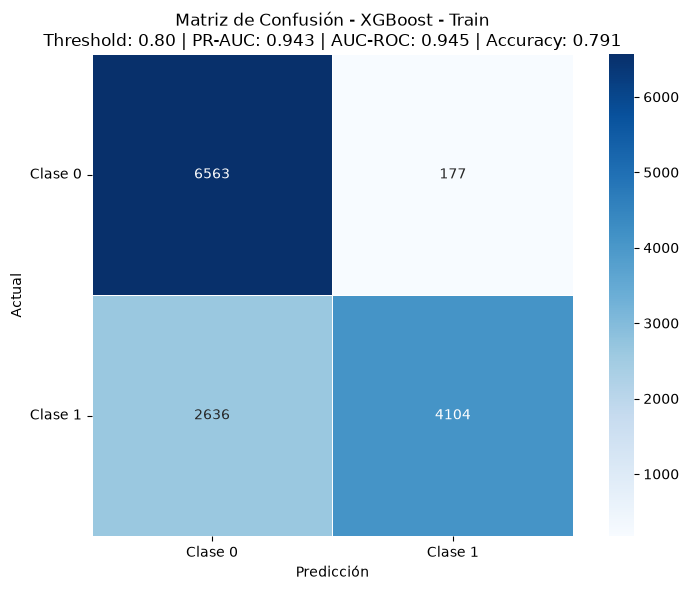


Reporte de Clasificación - XGBoost - Train
Threshold utilizado: 0.80

              precision    recall  f1-score   support

     Clase 0     0.7134    0.9737    0.8235      6740
     Clase 1     0.9587    0.6089    0.7448      6740

    accuracy                         0.7913     13480
   macro avg     0.8361    0.7913    0.7841     13480
weighted avg     0.8361    0.7913    0.7841     13480

PR-AUC: 0.9433
AUC-ROC: 0.9451
Accuracy: 0.7913


{'model_name': 'XGBoost - Train',
 'threshold': 0.8,
 'pr_auc': 0.9432627561863626,
 'auc_roc': 0.9450629353080506,
 'accuracy': 0.791320474777448,
 'confusion_matrix': array([[6563,  177],
        [2636, 4104]], dtype=int64),
 'y_pred': array([0, 0, 0, ..., 0, 0, 1])}

In [56]:
y_train_pred_proba = xgb_best.predict_proba(X_train_resampled)[:, 1]

plot_confusion_matrix_heatmap(
    y_true=y_train_resampled,
    y_pred_proba=y_train_pred_proba,
    model_name="XGBoost - Train",
    threshold=0.80
)

## Test Evaluation

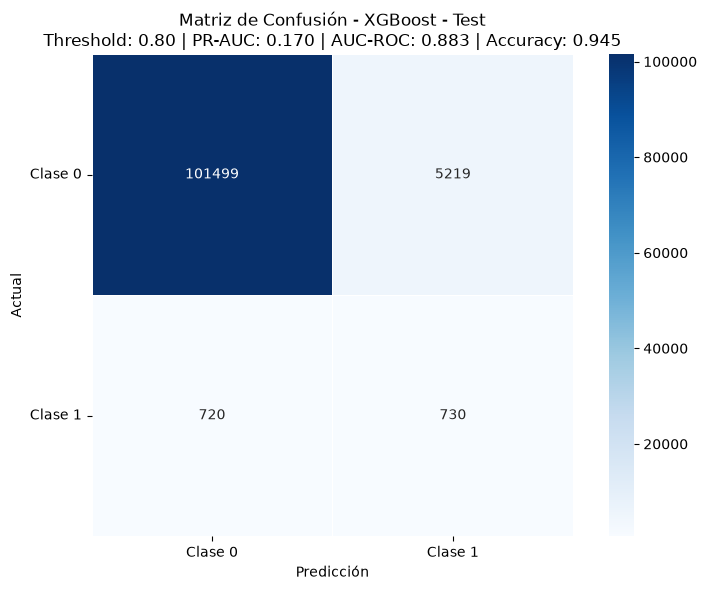


Reporte de Clasificación - XGBoost - Test
Threshold utilizado: 0.80

              precision    recall  f1-score   support

     Clase 0     0.9930    0.9511    0.9716    106718
     Clase 1     0.1227    0.5034    0.1973      1450

    accuracy                         0.9451    108168
   macro avg     0.5578    0.7273    0.5844    108168
weighted avg     0.9813    0.9451    0.9612    108168

PR-AUC: 0.1700
AUC-ROC: 0.8832
Accuracy: 0.9451


{'model_name': 'XGBoost - Test',
 'threshold': 0.8,
 'pr_auc': 0.16998692889163936,
 'auc_roc': 0.8831535513189449,
 'accuracy': 0.945094667554175,
 'confusion_matrix': array([[101499,   5219],
        [   720,    730]], dtype=int64),
 'y_pred': array([0, 0, 0, ..., 0, 0, 0])}

In [57]:
# Obtener las probabilidades predichas para la clase positiva
y_test_pred_proba = xgb_best.predict_proba(X_test)[:, 1]

# Evaluación usando un threshold de 0.85
plot_confusion_matrix_heatmap(
    y_true=y_test,
    y_pred_proba=y_test_pred_proba,
    model_name="XGBoost - Test",
    threshold=0.80
)

## OOT Evaluation

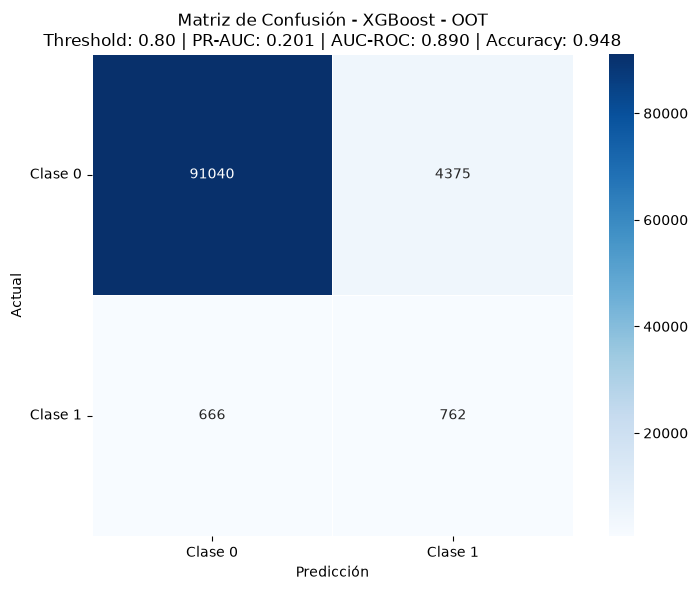


Reporte de Clasificación - XGBoost - OOT
Threshold utilizado: 0.80

              precision    recall  f1-score   support

     Clase 0     0.9927    0.9541    0.9731     95415
     Clase 1     0.1483    0.5336    0.2321      1428

    accuracy                         0.9479     96843
   macro avg     0.5705    0.7439    0.6026     96843
weighted avg     0.9803    0.9479    0.9621     96843

PR-AUC: 0.2010
AUC-ROC: 0.8896
Accuracy: 0.9479


{'model_name': 'XGBoost - OOT',
 'threshold': 0.8,
 'pr_auc': 0.2009815544965508,
 'auc_roc': 0.8895981302965038,
 'accuracy': 0.9479466765796185,
 'confusion_matrix': array([[91040,  4375],
        [  666,   762]], dtype=int64),
 'y_pred': array([0, 0, 0, ..., 0, 0, 0])}

In [58]:
y_oot_pred_proba = xgb_best.predict_proba(X_oot)[:, 1]

plot_confusion_matrix_heatmap(
    y_true=y_oot,
    y_pred_proba=y_oot_pred_proba,
    model_name="XGBoost - OOT",
    threshold=0.80
)

## Feature Importance

In [48]:
# Obtener la importancia de las características del modelo entrenado
feature_importance = xgb_best.feature_importances_

# Crear un DataFrame con la importancia de las características
feature_importance_df = pd.DataFrame({
    'Feature': X_train_resampled.columns,
    'Importance': feature_importance
})

# Ordenar el DataFrame por importancia de mayor a menor
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Configurar pandas para mostrar todas las filas
pd.set_option('display.max_rows', None)

# Mostrar el DataFrame completo
print(feature_importance_df)

# Restablecer la opción para no afectar otras salidas
pd.reset_option('display.max_rows')

                                                Feature  Importance
0                        categoricas__device_os_windows    0.164561
1                 numericas_mediana__device_trust_score    0.054324
2         sesgadas_constante__prev_address_months_count    0.054324
3                        categoricas__housing_status_BE    0.049588
4                    numericas_mediana__has_other_cards    0.049522
5                numericas_mediana__contact_consistency    0.043334
6                        categoricas__housing_status_BB    0.037256
7             numericas_mediana__digital_identity_score    0.036254
8                       numericas_mediana__customer_age    0.035137
9          numericas_mediana__device_distinct_emails_8w    0.034411
10                       categoricas__housing_status_BC    0.029258
11                            numericas_mediana__income    0.026991
12                    categoricas__employment_status_CF    0.026123
13                 numericas_mediana__credit_ris

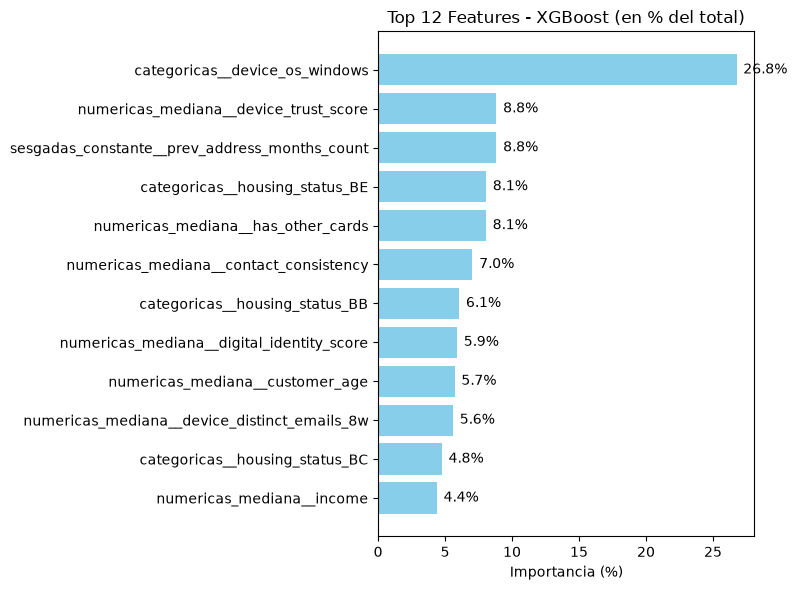

In [59]:
import matplotlib.pyplot as plt

# Top 20 características más importantes de XGBoost
top_n = 12
top_features_xgb = feature_importance_df.head(top_n).copy()

# Calcular el % sobre el total de importancia
total_importance = top_features_xgb['Importance'].sum()
top_features_xgb['Importance_pct'] = top_features_xgb['Importance'] / total_importance * 100

# Gráfico de barras horizontales
plt.figure(figsize=(8, 6))
bars = plt.barh(top_features_xgb['Feature'][::-1], top_features_xgb['Importance_pct'][::-1], color='skyblue')
plt.xlabel('Importancia (%)')
plt.title(f'Top {top_n} Features - XGBoost (en % del total)')

# Añadir etiquetas de % al final de cada barra
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.5,  # posición X ajustada para que no se encime
             bar.get_y() + bar.get_height() / 2,
             f'{width:.1f}%', va='center')

plt.tight_layout()
plt.show()
